##Step 1: Import Libraries and Load Data

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score
import warnings
warnings.filterwarnings('ignore')

matches = pd.read_csv('drive/MyDrive/Data Science Project/matches.csv')
deliveries = pd.read_csv('drive/MyDrive/Data Science Project/deliveries.csv')

print(f"Matches shape: {matches.shape}")
print(f"Deliveries shape: {deliveries.shape}")

Matches shape: (1095, 20)
Deliveries shape: (260920, 17)


##Step 2: Data Cleaning & Intelligent Imputation
###We intelligently standardize team names, filter for active franchises, and extract missing cities from the Venue names

In [ ]:
# Standardize team names
team_mapping = {
    'Delhi Daredevils': 'Delhi Capitals',
    'Deccan Chargers': 'Sunrisers Hyderabad',
    'Kings XI Punjab': 'Punjab Kings',
    'Royal Challengers Bangalore': 'Royal Challengers Bengaluru'
}

matches['team1'] = matches['team1'].replace(team_mapping)
matches['team2'] = matches['team2'].replace(team_mapping)
matches['winner'] = matches['winner'].replace(team_mapping)
matches['toss_winner'] = matches['toss_winner'].replace(team_mapping)

deliveries['batting_team'] = deliveries['batting_team'].replace(team_mapping)
deliveries['bowling_team'] = deliveries['bowling_team'].replace(team_mapping)

# Active teams
active_teams = [
    'Rajasthan Royals', 'Royal Challengers Bengaluru', 'Chennai Super Kings',
    'Delhi Capitals', 'Mumbai Indians', 'Kolkata Knight Riders',
    'Sunrisers Hyderabad', 'Punjab Kings', 'Lucknow Super Giants', 'Gujarat Titans'
]

# Filter datasets
matches = matches[(matches['team1'].isin(active_teams)) & (matches['team2'].isin(active_teams))]
deliveries = deliveries[(deliveries['batting_team'].isin(active_teams)) & (deliveries['bowling_team'].isin(active_teams))]

# Intelligent Missing Data Handling: Fill missing 'city' using the first word of the 'venue'
matches['city'] = matches['city'].fillna(matches['venue'].str.split().str[0])

# Extract necessary match info including toss, season, match_type, and venue
match_df = matches[['id', 'city', 'winner', 'target_runs', 'toss_winner', 'season', 'match_type', 'venue']]
dlv_df = deliveries[deliveries['inning'] == 2].copy()
df = dlv_df.merge(match_df, left_on='match_id', right_on='id')

# Drop unfixable NaNs
df.dropna(subset=['city', 'target_runs'], inplace=True)

##Step 3: Advanced Feature Engineering
###We calculate match situations ball-by-ball. This includes phases, momentum (last 30 balls), and home advantage. We strictly use fast, vectorized Pandas operations.

In [ ]:
# Sort data properly to ensure our rolling windows are chronologically correct
df = df.sort_values(['match_id', 'over', 'ball'])

# 1. Basic Match Context
df['current_score'] = df.groupby('match_id')['total_runs'].cumsum()
df['runs_left'] = np.where(df['target_runs'] - df['current_score'] >= 0, df['target_runs'] - df['current_score'], 0)
df['balls_bowled'] = (df['over'] * 6) + df['ball']
df['balls_left'] = np.where(120 - df['balls_bowled'] >= 0, 120 - df['balls_bowled'], 0)

# 2. Wickets Context
df['is_wicket'] = pd.to_numeric(df['is_wicket'], errors='coerce').fillna(0)
df['cumulative_wickets'] = df.groupby('match_id')['is_wicket'].cumsum()
df['wickets_left'] = 10 - df['cumulative_wickets']

# 3. Run Rates
df['crr'] = (df['current_score'] * 6) / df['balls_bowled']
df['rrr'] = np.where(df['balls_left'] == 0, 0, (df['runs_left'] * 6) / df['balls_left'])

# 4. MOMENTUM (Last 5 overs / 30 balls)
df['runs_last_30'] = df.groupby('match_id')['total_runs'].transform(lambda x: x.rolling(window=30, min_periods=1).sum())
df['wickets_last_30'] = df.groupby('match_id')['is_wicket'].transform(lambda x: x.rolling(window=30, min_periods=1).sum())

# 5. MATCH PHASES & TOSS ADVANTAGE
df['is_powerplay'] = np.where(df['over'] < 6, 1, 0)
df['is_death_over'] = np.where(df['over'] >= 15, 1, 0)
df['chasing_team_won_toss'] = np.where(df['batting_team'] == df['toss_winner'], 1, 0)

# 6. HOME CROWD ADVANTAGE
home_cities = {
    'Chennai Super Kings': 'Chennai', 'Mumbai Indians': 'Mumbai', 'Royal Challengers Bengaluru': 'Bengaluru',
    'Kolkata Knight Riders': 'Kolkata', 'Delhi Capitals': 'Delhi', 'Rajasthan Royals': 'Jaipur',
    'Sunrisers Hyderabad': 'Hyderabad', 'Punjab Kings': 'Chandigarh', 'Lucknow Super Giants': 'Lucknow',
    'Gujarat Titans': 'Ahmedabad'
}
df['is_home_advantage'] = np.where(df['city'] == df['batting_team'].map(home_cities), 1, 0)

df['result'] = (df['batting_team'] == df['winner']).astype(int)

# --- FINALIZE DATASET WITH MATCH DETAILS AND PLAYER INFO INCLUDED ---
final_df = df[['match_id', 'batting_team', 'bowling_team', 'city', 'runs_left', 'balls_left',
               'wickets_left', 'target_runs', 'crr', 'rrr', 'runs_last_30', 'wickets_last_30',
               'is_powerplay', 'is_death_over', 'chasing_team_won_toss', 'is_home_advantage',
               'result', 'over', 'ball', 'current_score', 'season', 'match_type', 'venue', 'batter', 'bowler']]

final_df.dropna(inplace=True)

# Drop text-based visual columns so the ML algorithm only gets the clean numbers
model_df = final_df.drop(['match_id', 'over', 'ball', 'current_score', 'season', 'match_type', 'venue', 'batter', 'bowler'], axis=1).sample(frac=1, random_state=42)

##Step 4: Model Building (Random Forest Pipeline)

###We train a powerful Random Forest model to predict the live win probability. Ensure this finishes running before moving to the visualizers!

In [ ]:
X = model_df.drop('result', axis=1)
y = model_df['result']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Encoding categorical columns (Added handle_unknown='ignore' as a safety net)
trf = ColumnTransformer([
    ('trf', OneHotEncoder(sparse_output=False, handle_unknown='ignore'), ['batting_team', 'bowling_team', 'city'])
], remainder='passthrough')

# Random Forest Pipeline
pipe = Pipeline(steps=[
    ('step1', trf),
    ('step2', RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1))
])

# Train Model
pipe.fit(X_train, y_train)

# Accuracy Check
y_pred = pipe.predict(X_test)
print(f"Random Forest Model Accuracy: {accuracy_score(y_test, y_pred)*100:.2f}%")
print("✅ Model is trained and ready! You can now run Step 5.")

Random Forest Model Accuracy: 89.81%
✅ Model is trained and ready! You can now run Step 5.


##Step 5: Complete Match TV-Style Dashboard (Historical)

###Search for any past match to see a beautiful TV-style broadcast dashboard featuring Win Probability, Run Rates, Momentum Heatmaps, Match Worm Graphs, and Player Impact.


✅ Match Found! Plotting: Chennai Super Kings vs Mumbai Indians (2023 - League)

🏏 MATCH SCOREBOARD SUMMARY: Mumbai Indians vs Chennai Super Kings
----------------------------------------------------------------------
🏆 Match Winner: Chennai Super Kings
🎯 Setting Target: Mumbai Indians
🏃 Chasing Target: Chennai Super Kings
📅 Season/Year: 2023      🏆 Match Type: League
🏟️ Venue: Wankhede Stadium, Mumbai
🎯 Target: 158.0 Runs
----------------------------------------------------------------------
🔥 1st Innings Top Scorers: Ishan Kishan (32), TH David (31), Tilak Varma (22)
🎯 1st Innings Top Bowlers: RA Jadeja (3W), MJ Santner (2W), TU Deshpande (2W)
🔥 2nd Innings Top Scorers: AM Rahane (61), RD Gaikwad (40), S Dube (28)
🎯 2nd Innings Top Bowlers: K Kartikeya (1W), JP Behrendorff (1W), PP Chawla (1W)
CLIMAX BALL-BY-BALL PROBABILITY (Last 10 Balls of the Innings):
Over.Ball Score  Runs Needed  Chennai Super Kings Win %  Mumbai Indians Win %
     16.6 140/3         18.0                       

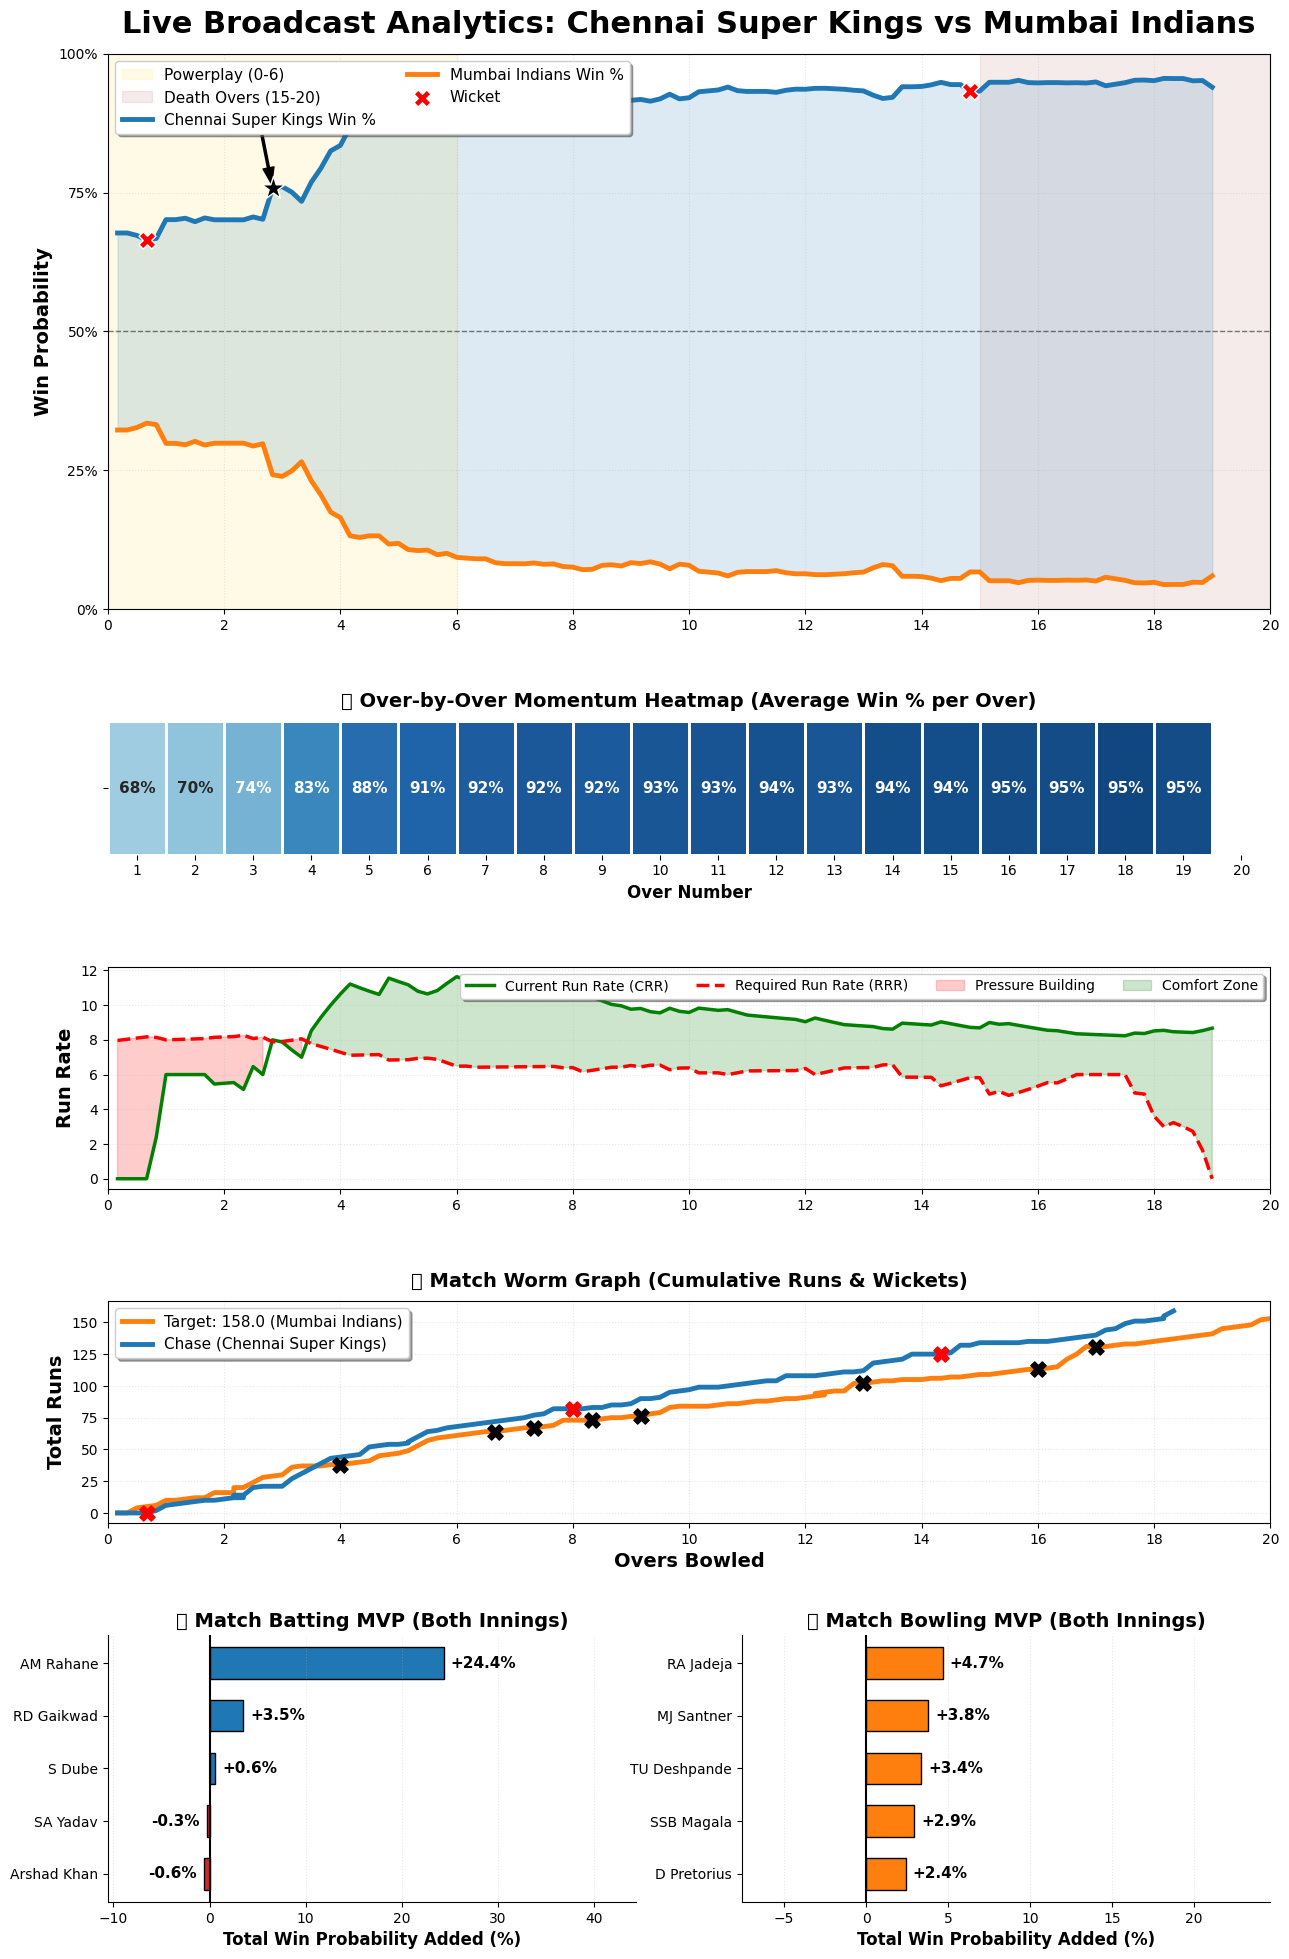

In [ ]:
# ==========================================================
# --- 🔍 INTERACTIVE MATCH SELECTION (COLAB NATIVE FORM) ---
# ==========================================================
# @title Find Your Match! { run: "auto", display-mode: "form" }
Team_1 = "Chennai" # @param {type:"string"}
Team_2 = "Mumbai" # @param {type:"string"}
Year = "2023" # @param {type:"string"}
Venue = "" # @param {type:"string"}

def plot_match_probability(match_id):
    # Extract match data chronologically
    match_data = final_df[final_df['match_id'] == match_id].sort_index()
    if match_data.empty: return

    batting_team, bowling_team = match_data['batting_team'].iloc[0], match_data['bowling_team'].iloc[0]

    wicket_indices = np.where(match_data['wickets_left'].diff() < 0)[0]

    drop_cols = ['match_id', 'result', 'over', 'ball', 'current_score', 'season', 'match_type', 'venue', 'batter', 'bowler']
    missing_cols = [col for col in drop_cols if col not in match_data.columns]

    if missing_cols:
        print(f"\n❌ AI ERROR: Memory Desync. Your dataset is missing: {missing_cols}")
        print("👉 SOLUTION: You have an old dataset in memory! Please scroll up, re-run 'Step 3', then 'Step 4', and try this again.")
        return

    features = match_data.drop(drop_cols, axis=1)

    try:
        probabilities = pipe.predict_proba(features)
    except Exception as e:
        print(f"\n❌ AI ERROR: Please run Step 4 first!")
        return

    win_prob_bowling, win_prob_batting = probabilities[:, 0], probabilities[:, 1]
    balls = np.arange(1, len(win_prob_batting) + 1)
    overs_bowled = balls / 6

    # --- VECTORIZED PLAYER IMPACT (WPA) CALCULATION (BOTH INNINGS!) ---
    full_match_dlv = deliveries[deliveries['match_id'] == match_id].copy()
    inn1_df = full_match_dlv[full_match_dlv['inning'] == 1].copy()

    inn1_bat_wpa_total = (win_prob_bowling[0] - 0.5) * 100
    inn1_bowl_wpa_total = (win_prob_batting[0] - 0.5) * 100

    if inn1_bat_wpa_total >= 0:
        inn1_bat_runs = inn1_df.groupby('batter')['batsman_runs'].sum()
        inn1_bat_wpa = (inn1_bat_runs / inn1_bat_runs.sum().clip(min=1)) * inn1_bat_wpa_total
    else:
        inn1_bat_balls = inn1_df.groupby('batter').size()
        inn1_bat_wpa = (inn1_bat_balls / inn1_bat_balls.sum().clip(min=1)) * inn1_bat_wpa_total

    inn1_df['is_wicket'] = pd.to_numeric(inn1_df['is_wicket'], errors='coerce').fillna(0)
    if inn1_bowl_wpa_total >= 0:
        inn1_bowl_wkts = inn1_df.groupby('bowler')['is_wicket'].sum()
        bowl_credit = inn1_bowl_wkts * 10 + inn1_df.groupby('bowler').size()
        inn1_bowl_wpa = (bowl_credit / bowl_credit.sum().clip(min=1)) * inn1_bowl_wpa_total
    else:
        inn1_bowl_runs = inn1_df.groupby('bowler')['total_runs'].sum()
        inn1_bowl_wpa = (inn1_bowl_runs / inn1_bowl_runs.sum().clip(min=1)) * inn1_bowl_wpa_total

    temp_df = match_data.copy()
    temp_df['bat_prob'] = win_prob_batting
    temp_df['prob_shift'] = temp_df['bat_prob'].diff().fillna(0)

    inn2_bat_wpa = temp_df.groupby('batter')['prob_shift'].sum() * 100
    inn2_bowl_wpa = temp_df.groupby('bowler')['prob_shift'].sum() * -100

    all_bat_wpa = pd.concat([inn1_bat_wpa, inn2_bat_wpa]).groupby(level=0).sum()
    all_bowl_wpa = pd.concat([inn1_bowl_wpa, inn2_bowl_wpa]).groupby(level=0).sum()

    top_batters = all_bat_wpa.sort_values(ascending=True).tail(5)
    top_bowlers = all_bowl_wpa.sort_values(ascending=True).tail(5)

    # --- VECTORIZED MOMENTUM SHIFT HEATMAP CALCULATION ---
    over_probs = temp_df.groupby('over')['bat_prob'].mean()
    heatmap_data = over_probs.reindex(np.arange(20)).values.reshape(1, 20)
    heatmap_df = pd.DataFrame(heatmap_data, columns=np.arange(1, 21).astype(str), index=[''])

    if len(win_prob_batting) > 1:
        prob_shifts_abs = np.abs(np.diff(win_prob_batting))
        turning_point_idx = np.argmax(prob_shifts_abs) + 1
        tp_over = overs_bowled[turning_point_idx]
        tp_prob = win_prob_batting[turning_point_idx]
        tp_shift_text = f"({prob_shifts_abs[turning_point_idx-1]*100:.1f}% shift)"
    else:
        tp_over = overs_bowled[0]
        tp_prob = win_prob_batting[0]
        tp_shift_text = ""

    over_ball_col = match_data['over'].astype(str) + "." + match_data['ball'].astype(str)
    wickets_fallen = 10 - match_data['wickets_left']

    scoreboard_df = pd.DataFrame({
        'Over.Ball': over_ball_col,
        'Score': match_data['current_score'].astype(str) + "/" + wickets_fallen.astype(str),
        'Runs Needed': match_data['runs_left'],
        f'{batting_team} Win %': np.round(win_prob_batting * 100, 1),
        f'{bowling_team} Win %': np.round(win_prob_bowling * 100, 1)
    })

    season = match_data['season'].iloc[0]
    match_type = match_data['match_type'].iloc[0]
    venue = match_data['venue'].iloc[0]
    target_runs = match_data['target_runs'].iloc[0]
    match_winner = batting_team if match_data['result'].iloc[-1] == 1 else bowling_team

    inn1_runs = inn1_df.groupby('batter')['batsman_runs'].sum().sort_values(ascending=False).head(3)
    inn1_top_batters = (inn1_runs.index + " (" + inn1_runs.astype(str) + ")").str.cat(sep=", ") if not inn1_runs.empty else "N/A"

    inn1_wkts = inn1_df.groupby('bowler')['is_wicket'].sum().sort_values(ascending=False).head(3)
    inn1_wkts = inn1_wkts[inn1_wkts > 0]
    inn1_top_bowlers = (inn1_wkts.index + " (" + inn1_wkts.astype(int).astype(str) + "W)").str.cat(sep=", ") if not inn1_wkts.empty else "None"

    inn2_df = full_match_dlv[full_match_dlv['inning'] == 2].copy()
    inn2_df['is_wicket'] = pd.to_numeric(inn2_df['is_wicket'], errors='coerce').fillna(0)

    inn2_runs = inn2_df.groupby('batter')['batsman_runs'].sum().sort_values(ascending=False).head(3)
    inn2_top_batters = (inn2_runs.index + " (" + inn2_runs.astype(str) + ")").str.cat(sep=", ") if not inn2_runs.empty else "N/A"

    inn2_wkts = inn2_df.groupby('bowler')['is_wicket'].sum().sort_values(ascending=False).head(3)
    inn2_wkts = inn2_wkts[inn2_wkts > 0]
    inn2_top_bowlers = (inn2_wkts.index + " (" + inn2_wkts.astype(int).astype(str) + "W)").str.cat(sep=", ") if not inn2_wkts.empty else "None"

    print("\n" + "="*70)
    print(f"🏏 MATCH SCOREBOARD SUMMARY: {bowling_team} vs {batting_team}")
    print("-" * 70)
    print(f"🏆 Match Winner: {match_winner}")
    print(f"🎯 Setting Target: {bowling_team}")
    print(f"🏃 Chasing Target: {batting_team}")
    print(f"📅 Season/Year: {season}      🏆 Match Type: {match_type}")
    print(f"🏟️ Venue: {venue}")
    print(f"🎯 Target: {target_runs} Runs")
    print("-" * 70)
    print(f"🔥 1st Innings Top Scorers: {inn1_top_batters}")
    print(f"🎯 1st Innings Top Bowlers: {inn1_top_bowlers}")
    print(f"🔥 2nd Innings Top Scorers: {inn2_top_batters}")
    print(f"🎯 2nd Innings Top Bowlers: {inn2_top_bowlers}")
    print("="*70)
    print("CLIMAX BALL-BY-BALL PROBABILITY (Last 10 Balls of the Innings):")
    print(scoreboard_df.tail(10).to_string(index=False))
    print("="*70 + "\n")

    # =====================================================================
    # --- VECTORIZED WORM GRAPH DATA (CUMULATIVE RUNS) ---
    # =====================================================================
    inn1_df_sorted = inn1_df.sort_values(['over', 'ball'])
    inn2_df_sorted = inn2_df.sort_values(['over', 'ball'])

    inn1_df_sorted['cum_runs'] = inn1_df_sorted['total_runs'].cumsum()
    inn2_df_sorted['cum_runs'] = inn2_df_sorted['total_runs'].cumsum()

    inn1_overs = inn1_df_sorted['over'] + (inn1_df_sorted['ball'] / 6.0)
    inn2_overs = inn2_df_sorted['over'] + (inn2_df_sorted['ball'] / 6.0)

    inn1_wkts_df = inn1_df_sorted[inn1_df_sorted['is_wicket'] == 1]
    inn2_wkts_df = inn2_df_sorted[inn2_df_sorted['is_wicket'] == 1]

    inn1_wkt_overs = inn1_wkts_df['over'] + (inn1_wkts_df['ball'] / 6.0)
    inn2_wkt_overs = inn2_wkts_df['over'] + (inn2_wkts_df['ball'] / 6.0)


    # --- PLOT THE DASHBOARD ---
    # Increased figsize and grid rows to 5 to accommodate the Worm Graph perfectly!
    fig = plt.figure(figsize=(15, 24))
    gs = fig.add_gridspec(5, 2, height_ratios=[2.5, 0.6, 1, 1, 1.2], hspace=0.4, wspace=0.2)

    ax1 = fig.add_subplot(gs[0, :])
    ax_hm = fig.add_subplot(gs[1, :])
    ax2 = fig.add_subplot(gs[2, :], sharex=ax1)
    ax_worm = fig.add_subplot(gs[3, :], sharex=ax1) # The new Worm Graph!
    ax3 = fig.add_subplot(gs[4, 0])
    ax4 = fig.add_subplot(gs[4, 1])

    # 1. Win Probability
    ax1.axvspan(0, 6, color='gold', alpha=0.1, label='Powerplay (0-6)')
    ax1.axvspan(15, 20, color='darkred', alpha=0.08, label='Death Overs (15-20)')

    ax1.plot(overs_bowled, win_prob_batting, color='#1f77b4', linewidth=3.5, label=f'{batting_team} Win %')
    ax1.plot(overs_bowled, win_prob_bowling, color='#ff7f0e', linewidth=3.5, label=f'{bowling_team} Win %')

    ax1.fill_between(overs_bowled, win_prob_batting, win_prob_bowling, where=(win_prob_batting >= win_prob_bowling), color='#1f77b4', alpha=0.15)
    ax1.fill_between(overs_bowled, win_prob_batting, win_prob_bowling, where=(win_prob_batting < win_prob_bowling), color='#ff7f0e', alpha=0.15)

    if len(wicket_indices) > 0:
        ax1.scatter(overs_bowled[wicket_indices], win_prob_batting[wicket_indices], color='red', s=150, zorder=5, edgecolors='white', marker='X', label='Wicket')

    ax1.scatter(tp_over, tp_prob, color='black', s=300, zorder=6, edgecolors='white', marker='*')
    ax1.annotate(f'🎯 Turning Point\n{tp_shift_text}',
                 xy=(tp_over, tp_prob), xytext=(tp_over-2.5, tp_prob+0.15),
                 arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=8),
                 fontsize=11, fontweight='bold', bbox=dict(boxstyle="round,pad=0.3", fc="yellow", ec="black", lw=1))

    ax1.axhline(0.5, color='black', linestyle='--', linewidth=1, alpha=0.5)
    ax1.set_title(f'Live Broadcast Analytics: {batting_team} vs {bowling_team}', fontsize=22, fontweight='900', pad=15)
    ax1.set_ylabel('Win Probability', fontsize=14, fontweight='bold')
    ax1.set_ylim(0, 1)
    ax1.set_yticks([0, 0.25, 0.5, 0.75, 1.0], ['0%', '25%', '50%', '75%', '100%'])
    ax1.legend(loc='upper left', fancybox=True, shadow=True, ncol=2, fontsize=11)
    ax1.grid(alpha=0.3, linestyle=':')

    # 2. Heatmap
    sns.heatmap(heatmap_df, cmap='RdBu', vmin=0, vmax=1, annot=True, fmt=".0%",
                cbar=False, ax=ax_hm, linewidths=2, linecolor='white',
                annot_kws={'fontsize': 11, 'fontweight': 'bold'})
    ax_hm.set_title('🔥 Over-by-Over Momentum Heatmap (Average Win % per Over)', fontsize=14, fontweight='bold', pad=10)
    ax_hm.set_xlabel('Over Number', fontsize=12, fontweight='bold')

    # 3. Run Rates
    crr_values = match_data['crr']
    rrr_values = match_data['rrr']

    ax2.plot(overs_bowled, crr_values, color='green', linewidth=2.5, label='Current Run Rate (CRR)')
    ax2.plot(overs_bowled, rrr_values, color='red', linewidth=2.5, linestyle='--', label='Required Run Rate (RRR)')

    ax2.fill_between(overs_bowled, crr_values, rrr_values, where=(rrr_values > crr_values), color='red', alpha=0.2, label='Pressure Building')
    ax2.fill_between(overs_bowled, crr_values, rrr_values, where=(crr_values >= rrr_values), color='green', alpha=0.2, label='Comfort Zone')

    ax2.set_ylabel('Run Rate', fontsize=14, fontweight='bold')
    ax2.legend(loc='upper right', fancybox=True, shadow=True, ncol=4, fontsize=10)
    ax2.grid(alpha=0.3, linestyle=':')

    # 4. WORM GRAPH (New!)
    ax_worm.plot(inn1_overs, inn1_df_sorted['cum_runs'], color='#ff7f0e', linewidth=3.5, label=f'Target: {target_runs} ({bowling_team})')
    ax_worm.plot(inn2_overs, inn2_df_sorted['cum_runs'], color='#1f77b4', linewidth=3.5, label=f'Chase ({batting_team})')

    # Scatter Wickets on the Worm Graph
    if not inn1_wkts_df.empty:
        ax_worm.scatter(inn1_wkt_overs, inn1_wkts_df['cum_runs'], color='black', s=120, zorder=5, marker='X')
    if not inn2_wkts_df.empty:
        ax_worm.scatter(inn2_wkt_overs, inn2_wkts_df['cum_runs'], color='red', s=120, zorder=5, marker='X')

    ax_worm.set_title('🐛 Match Worm Graph (Cumulative Runs & Wickets)', fontsize=14, fontweight='bold', pad=10)
    ax_worm.set_xlabel('Overs Bowled', fontsize=14, fontweight='bold')
    ax_worm.set_ylabel('Total Runs', fontsize=14, fontweight='bold')
    ax_worm.set_xticks(np.arange(0, 21, 2))
    ax_worm.set_xlim(0, 20)
    ax_worm.legend(loc='upper left', fancybox=True, shadow=True, fontsize=11)
    ax_worm.grid(alpha=0.3, linestyle=':')

    # 5. Batting MVP
    bar_colors_bat = np.where(top_batters > 0, '#1f77b4', '#d62728').tolist()
    bars_bat = ax3.barh(top_batters.index, top_batters.values, color=bar_colors_bat, edgecolor='black', height=0.6)

    ax3.axvline(0, color='black', linewidth=1.5)
    ax3.bar_label(bars_bat, fmt='%+.1f%%', padding=5, fontsize=11, fontweight='bold')

    ax3.set_title(f'👑 Match Batting MVP (Both Innings)', fontsize=14, fontweight='bold')
    ax3.set_xlabel('Total Win Probability Added (%)', fontsize=12, fontweight='bold')
    ax3.set_xlim(min(0, top_batters.min() - 10), top_batters.max() + 20)
    ax3.grid(axis='x', alpha=0.3, linestyle=':')
    ax3.spines['top'].set_visible(False)
    ax3.spines['right'].set_visible(False)

    # 6. Bowling MVP
    bar_colors_bowl = np.where(top_bowlers > 0, '#ff7f0e', '#d62728').tolist()
    bars_bowl = ax4.barh(top_bowlers.index, top_bowlers.values, color=bar_colors_bowl, edgecolor='black', height=0.6)

    ax4.axvline(0, color='black', linewidth=1.5)
    ax4.bar_label(bars_bowl, fmt='%+.1f%%', padding=5, fontsize=11, fontweight='bold')

    ax4.set_title(f'🎯 Match Bowling MVP (Both Innings)', fontsize=14, fontweight='bold')
    ax4.set_xlabel('Total Win Probability Added (%)', fontsize=12, fontweight='bold')
    ax4.set_xlim(min(0, top_bowlers.min() - 10), top_bowlers.max() + 20)
    ax4.grid(axis='x', alpha=0.3, linestyle=':')
    ax4.spines['top'].set_visible(False)
    ax4.spines['right'].set_visible(False)

    plt.tight_layout()
    plt.show()

# --- TRIGGER THE SEARCH ---
team1_query = Team_1.strip()
team2_query = Team_2.strip()
year_query = str(Year).strip()
venue_query = str(Venue).strip()

unique_matches = final_df[['match_id', 'batting_team', 'bowling_team', 'season', 'match_type', 'venue', 'city']].drop_duplicates()

mask_team1 = unique_matches['batting_team'].str.contains(team1_query, case=False, na=False, regex=False) | unique_matches['bowling_team'].str.contains(team1_query, case=False, na=False, regex=False)
mask_team2 = unique_matches['batting_team'].str.contains(team2_query, case=False, na=False, regex=False) | unique_matches['bowling_team'].str.contains(team2_query, case=False, na=False, regex=False)
mask_year = unique_matches['season'].astype(str).str.contains(year_query, case=False, na=False, regex=False)
mask_venue = unique_matches['venue'].str.contains(venue_query, case=False, na=False, regex=False) | unique_matches['city'].str.contains(venue_query, case=False, na=False, regex=False)

found_matches = unique_matches[mask_team1 & mask_team2 & mask_year & mask_venue]

if not found_matches.empty:
    selected_match_id = found_matches['match_id'].iloc[0]
    match_desc = f"{found_matches['batting_team'].iloc[0]} vs {found_matches['bowling_team'].iloc[0]}"
    print(f"\n✅ Match Found! Plotting: {match_desc} ({found_matches['season'].iloc[0]} - {found_matches['match_type'].iloc[0]})")
    plot_match_probability(selected_match_id)
else:
    print("\n❌ No match found with those details. Please check the spelling or try a different year/venue in the form.")

##Step 6: Live Match Predictor (Win Probability + RRR Horizon)

###Manually input any live match scenario. If the team is chasing (2nd Innings), the dashboard dynamically expands to display the Future Pressure Horizon (RRR trajectory). Built completely loop-free.


🔮 LIVE MATCH COMMAND CENTER: Mumbai Indians vs Punjab Kings
📍 Venue: Chennai | 📊 Current Phase: 1st Innings (Setting Target)
🏏 Score: 170/3 (18 Overs) | CRR: 9.44
🎯 Setting Target: Mumbai Indians
🏃 Chasing Target: Punjab Kings (Yet to bat)
🏟️ Historical Average 1st Innings Score at Chennai: 165
🎯 AI Projected Target based on Current Rate + History: 177
------------------------------------------------------------
🟢 Punjab Kings Win Probability: 34.5%
🔴 Mumbai Indians Win Probability: 65.5%



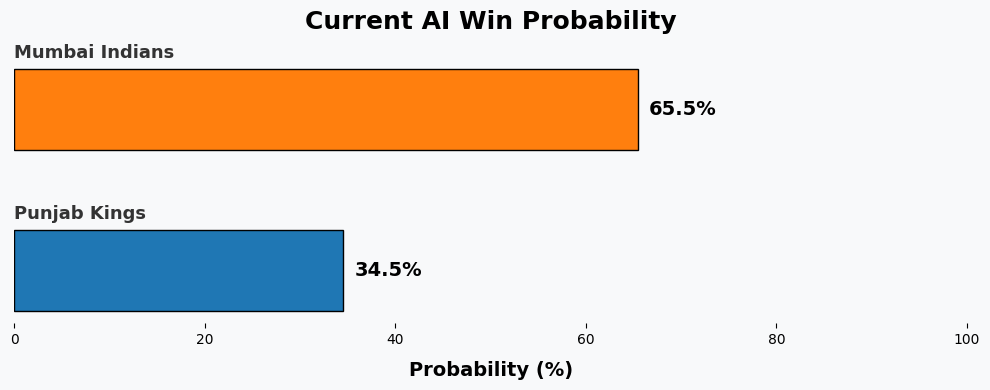

In [ ]:
# ==========================================================
# --- 🔮 STEP 6: LIVE MATCH STATE PREDICTOR (NO LOOPS) ---
# ==========================================================
# @title Live Match Simulator { run: "auto", display-mode: "form" }
Batting_Team = "Mumbai Indians" # @param ["Chennai Super Kings", "Mumbai Indians", "Royal Challengers Bengaluru", "Kolkata Knight Riders", "Delhi Capitals", "Rajasthan Royals", "Sunrisers Hyderabad", "Punjab Kings", "Lucknow Super Giants", "Gujarat Titans"]
Bowling_Team = "Punjab Kings" # @param ["Chennai Super Kings", "Mumbai Indians", "Royal Challengers Bengaluru", "Kolkata Knight Riders", "Delhi Capitals", "Rajasthan Royals", "Sunrisers Hyderabad", "Punjab Kings", "Lucknow Super Giants", "Gujarat Titans"]
City = "Chennai" # @param ["Ahmedabad", "Bengaluru", "Chennai", "Delhi", "Hyderabad", "Jaipur", "Kolkata", "Lucknow", "Mumbai", "Chandigarh"]
Innings = "1st Innings (Setting Target)" # @param ["1st Innings (Setting Target)", "2nd Innings (Chasing)"]
Current_Score = 170 # @param {type:"integer"}
Wickets_Lost = 3 # @param {type:"integer"}
Overs_Bowled = 18 # @param {type:"number"}
Target_Score = 200 # @param {type:"integer"}

# 🛡️ BULLETPROOF SAFEGUARD
try:
    _ = matches
    _ = pipe

    home_cities = {
        'Chennai Super Kings': 'Chennai', 'Mumbai Indians': 'Mumbai', 'Royal Challengers Bengaluru': 'Bengaluru',
        'Kolkata Knight Riders': 'Kolkata', 'Delhi Capitals': 'Delhi', 'Rajasthan Royals': 'Jaipur',
        'Sunrisers Hyderabad': 'Hyderabad', 'Punjab Kings': 'Chandigarh', 'Lucknow Super Giants': 'Lucknow',
        'Gujarat Titans': 'Ahmedabad'
    }

    # 1. Instantly calculate constraints
    balls_bowled = int(Overs_Bowled) * 6 + int(round((Overs_Bowled % 1) * 10))
    balls_left = 120 - balls_bowled
    wickets_left = 10 - Wickets_Lost
    crr = (Current_Score * 6) / balls_bowled if balls_bowled > 0 else 0

    is_powerplay_est = 1 if Overs_Bowled < 6 else 0
    is_death_over_est = 1 if Overs_Bowled >= 15 else 0

    print("\n" + "="*60)
    print(f"🔮 LIVE MATCH COMMAND CENTER: {Batting_Team} vs {Bowling_Team}")
    print("="*60)
    print(f"📍 Venue: {City} | 📊 Current Phase: {Innings}")
    print(f"🏏 Score: {Current_Score}/{Wickets_Lost} ({Overs_Bowled} Overs) | CRR: {crr:.2f}")

    if "1st" in Innings:
        venue_avg = matches[matches['city'] == City]['target_runs'].mean()
        venue_avg = venue_avg if pd.notna(venue_avg) else 165.0

        crr_projection = Current_Score + (crr * (balls_left / 6))
        projected_target = int((crr_projection + venue_avg) / 2)

        setting_team = Batting_Team
        chasing_team = Bowling_Team
        target = projected_target
        current_runs_left = projected_target
        current_balls_left = 120
        current_wickets_left = 10
        runs_last_30_est = 0
        wickets_last_30_est = 0
        is_powerplay_now = 1
        is_death_now = 0

        rrr = (current_runs_left * 6) / current_balls_left if current_balls_left > 0 else 0
        print(f"🎯 Setting Target: {setting_team}")
        print(f"🏃 Chasing Target: {chasing_team} (Yet to bat)")
        print(f"🏟️ Historical Average 1st Innings Score at {City}: {int(venue_avg)}")
        print(f"🎯 AI Projected Target based on Current Rate + History: {target}")

    else:
        setting_team = Bowling_Team
        chasing_team = Batting_Team
        target = Target_Score
        current_runs_left = Target_Score - Current_Score
        current_balls_left = balls_left
        current_wickets_left = wickets_left

        runs_last_30_est = min(Current_Score, crr * 5) if balls_bowled >= 30 else Current_Score
        wickets_last_30_est = round((Wickets_Lost / balls_bowled) * 30) if balls_bowled > 0 else 0
        is_powerplay_now = is_powerplay_est
        is_death_now = is_death_over_est

        rrr = (current_runs_left * 6) / current_balls_left if current_balls_left > 0 else 0
        print(f"🎯 Setting Target: {setting_team} (Target: {target})")
        print(f"🏃 Chasing Target: {chasing_team}")
        print(f"📉 Runs Needed: {current_runs_left} from {current_balls_left} balls | RRR: {rrr:.2f}")

    # Build current state dataframe
    sim_df = pd.DataFrame({
        'batting_team': [chasing_team], 'bowling_team': [setting_team], 'city': [City],
        'runs_left': [current_runs_left], 'balls_left': [current_balls_left], 'wickets_left': [current_wickets_left],
        'target_runs': [target], 'crr': [crr if "2nd" in Innings else 0.0],
        'rrr': [rrr],
        'runs_last_30': [runs_last_30_est], 'wickets_last_30': [wickets_last_30_est],
        'is_powerplay': [is_powerplay_now], 'is_death_over': [is_death_now],
        'chasing_team_won_toss': [0], 'is_home_advantage': [1 if City == home_cities.get(chasing_team) else 0]
    })

    pred = pipe.predict_proba(sim_df)[0]
    chase_win_prob = pred[1] * 100
    defend_win_prob = pred[0] * 100

    print("-" * 60)
    print(f"🟢 {chasing_team} Win Probability: {chase_win_prob:.1f}%")
    print(f"🔴 {setting_team} Win Probability: {defend_win_prob:.1f}%")
    print("="*60 + "\n")

    # =====================================================================
    # --- DYNAMIC DASHBOARD (Win Prob + Optional RRR Horizon) ---
    # =====================================================================
    if "2nd" in Innings and current_balls_left > 1:
        # Taller layout to fit the horizon graph below
        fig = plt.figure(figsize=(12, 10), facecolor='#f8f9fa')
        gs = fig.add_gridspec(2, 1, height_ratios=[1, 1.5], hspace=0.4)
        ax1 = fig.add_subplot(gs[0, 0])
    else:
        # Standard clean layout
        fig = plt.figure(figsize=(10, 4), facecolor='#f8f9fa')
        ax1 = plt.gca()

    ax1.set_facecolor('#f8f9fa')

    teams = [chasing_team, setting_team]
    probs = [chase_win_prob, defend_win_prob]
    colors = ['#1f77b4', '#ff7f0e']

    bars = ax1.barh([0, 1], probs, color=colors, edgecolor='black', height=0.5)
    ax1.bar_label(bars, fmt='%.1f%%', padding=8, fontsize=14, fontweight='bold')

    ax1.set_title('Current AI Win Probability', fontsize=18, fontweight='900', pad=20)
    ax1.set_xlabel('Probability (%)', fontsize=14, fontweight='bold', labelpad=10)
    ax1.set_xlim(0, 100)

    ax1.spines[['top', 'right', 'bottom', 'left']].set_visible(False)
    ax1.set_yticks([])
    ax1.text(0, 0 + 0.35, teams[0], va='center', ha='left', fontsize=13, fontweight='bold', color='#333333')
    ax1.text(0, 1 + 0.35, teams[1], va='center', ha='left', fontsize=13, fontweight='bold', color='#333333')

    # =====================================================================
    # --- VECTORIZED "FUTURE RRR HORIZON" (ONLY IF 2ND INNINGS) ---
    # =====================================================================
    if "2nd" in Innings:
        horizon_balls = min(12, current_balls_left - 1) if current_balls_left > 1 else 0

        if horizon_balls > 0:
            ax2 = fig.add_subplot(gs[1, 0])
            ax2.set_facecolor('#f8f9fa')

            # Purely Vectorized Mathematical Projections
            ball_range = np.arange(1, horizon_balls + 1)
            future_balls_arr = current_balls_left - ball_range

            rrr_dots = (current_runs_left * 6) / future_balls_arr
            rrr_singles = ((current_runs_left - ball_range) * 6) / future_balls_arr
            rrr_aggressive = ((current_runs_left - (ball_range * 2)) * 6) / future_balls_arr

            ax2.plot(ball_range, rrr_dots, color='#d62728', linewidth=3, marker='o', markersize=8, label='Total Choke (0 Runs per Ball)')
            ax2.plot(ball_range, rrr_singles, color='#1f77b4', linewidth=3, marker='s', markersize=8, label='Ticking Over (1 Run per Ball)')
            ax2.plot(ball_range, rrr_aggressive, color='#2ca02c', linewidth=3, marker='^', markersize=8, label='Aggressive (2 Runs per Ball)')

            ax2.axhline(rrr, color='black', linestyle='--', linewidth=2, label=f'Current RRR ({rrr:.2f})')

            # Formatting
            ax2.set_title(f'Future Pressure Horizon: RRR Trajectory over the next {horizon_balls} balls', fontsize=16, fontweight='bold', pad=15)
            ax2.set_xlabel('Next Deliveries Simulated', fontsize=12, fontweight='bold')
            ax2.set_ylabel('Required Run Rate (RRR)', fontsize=12, fontweight='bold')
            ax2.set_xticks(ball_range)
            ax2.legend(loc='upper left', frameon=True, shadow=True, fontsize=11)
            ax2.spines[['top', 'right']].set_visible(False)
            ax2.grid(alpha=0.3, linestyle=':')

    plt.tight_layout()
    plt.show()

except NameError:
    print("\n❌ AI ERROR: Required Data Missing From Memory!")
    print("👉 SOLUTION: Colab forgot the variables. Please scroll up and run 'Step 1' (to load data) and 'Step 4' (to train the model), then try this simulator again.")

##Step 7: Overall Model Interpretability (Global Importance)

###Understand exactly which overall match conditions matter most to our Random Forest algorithm across the entire history of the IPL.

🏆 FEATURE IMPORTANCE SCOREBOARD
          Match Feature Model Weight (%)
        Wickets in Hand            7.95%
            Runs Needed            6.51%
 Current Run Rate (CRR)            4.57%
 Wickets (Last 5 Overs)            4.35%
Required Run Rate (RRR)            33.0%
        Balls Remaining            2.28%
     Total Target Score           18.08%
    Runs (Last 5 Overs)            1.72%
   Home Crowd Advantage            1.06%
         Toss Advantage            1.02%
     Phase: Death Overs            0.56%
       Phase: Powerplay            0.41%



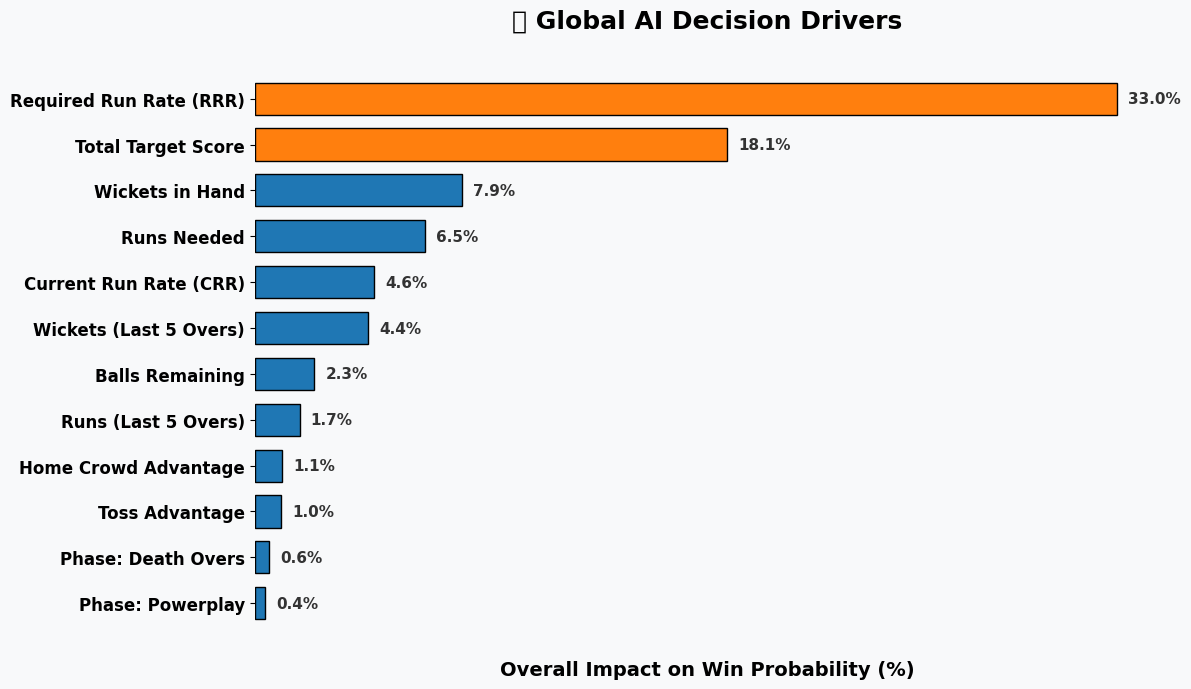

In [ ]:
# Extract feature names
ohe_features = pipe.named_steps['step1'].named_transformers_['trf'].get_feature_names_out()
num_features = ['runs_left', 'balls_left', 'wickets_left', 'target_runs', 'crr', 'rrr', 'runs_last_30', 'wickets_last_30', 'is_powerplay', 'is_death_over', 'chasing_team_won_toss', 'is_home_advantage']
all_features = np.concatenate([ohe_features, num_features])

# Get importances and create DataFrame
importances = pipe.named_steps['step2'].feature_importances_
importance_df = pd.DataFrame({'Feature': all_features, 'Importance': importances})

# Filter numerical features
core_stats = importance_df[importance_df['Feature'].isin(num_features)].sort_values(by='Importance', ascending=True)

# Map names for readability
feature_mapping = {
    'rrr': 'Required Run Rate (RRR)', 'runs_left': 'Runs Needed', 'crr': 'Current Run Rate (CRR)',
    'balls_left': 'Balls Remaining', 'wickets_left': 'Wickets in Hand', 'runs_last_30': 'Runs (Last 5 Overs)',
    'target_runs': 'Total Target Score', 'wickets_last_30': 'Wickets (Last 5 Overs)',
    'is_powerplay': 'Phase: Powerplay', 'is_death_over': 'Phase: Death Overs',
    'chasing_team_won_toss': 'Toss Advantage', 'is_home_advantage': 'Home Crowd Advantage'
}
core_stats['Display_Feature'] = core_stats['Feature'].map(feature_mapping)
core_stats['Importance_Pct'] = core_stats['Importance'] * 100

# --- 🏆 PRINT FEATURE IMPORTANCE SCOREBOARD TO CONSOLE ---
print("="*50)
print("🏆 FEATURE IMPORTANCE SCOREBOARD")
print("="*50)
scoreboard_display = core_stats[['Display_Feature', 'Importance_Pct']].copy()
scoreboard_display['Importance_Pct'] = scoreboard_display['Importance_Pct'].round(2).astype(str) + '%'
scoreboard_display = scoreboard_display.sort_values(by='Importance_Pct', ascending=False)
print(scoreboard_display.to_string(index=False, header=['Match Feature', 'Model Weight (%)']))
print("="*50 + "\n")

# Plotting
top_features = core_stats['Display_Feature'].tail(2).values
colors = np.where(core_stats['Display_Feature'].isin(top_features), '#ff7f0e', '#1f77b4')

plt.figure(figsize=(12, 7), facecolor='#f8f9fa')
ax = plt.gca()
ax.set_facecolor('#f8f9fa')

bars = ax.barh(core_stats['Display_Feature'], core_stats['Importance_Pct'], color=colors, height=0.7, edgecolor='black')
ax.bar_label(bars, fmt='%.1f%%', padding=8, fontsize=11, fontweight='bold', color='#333333')

plt.title('🧠 Global AI Decision Drivers', fontsize=18, fontweight='900', pad=20)
plt.xlabel('Overall Impact on Win Probability (%)', fontsize=14, fontweight='bold', labelpad=10)

ax.spines[['top', 'right', 'bottom', 'left']].set_visible(False)
plt.xticks([])
plt.yticks(fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
